# 🐱🐶 Image classification with Keras: Cat or Dog?

**Goal:** Give a CNN a photograph and ask it to predict **one label for the whole image**: `cat` or `dog`.

This is different from our segmentation lesson: **we do not need masks**. Each code cell has a small task, explained in plain language. Run the cells from top to bottom.

## Step 1 — Prepare your images

**Option A (simplest, recommended):** Put photographs into two named folders:

```text
animal_dataset/
    cats/
        cat1.jpg
        cat2.jpg
    dogs/
        dog1.jpg
        dog2.jpg
```

**Option B (your previous Oxford-IIIT Pet layout):** Keep the original photos in `animal_dataset/animals/`. The notebook can infer cat/dog labels from the **official Oxford breed filenames** (for example, `Abyssinian_1.jpg` → cat; `beagle_1.jpg` → dog). This works for the official, unchanged Oxford filenames, not arbitrary filenames.

The `masks/` directory can stay in place; classification does **not** use it.

## Step 2 — Install libraries (only if needed)

In [1]:
# Uncomment this line and run it only if a library is missing.
# %pip install tensorflow pandas numpy matplotlib pillow scikit-learn

## Step 3 — Import libraries

These are ready-made tools for reading images, organizing a DataFrame, building a CNN, and drawing charts.

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import tensorflow as tf

SEED = 42
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.22.0-rc0


## Step 4 — Choose the dataset folder and image size

Change `DATA_FOLDER` if your dataset is elsewhere. Start with small images to train a simple CNN quickly.

In [3]:
DATA_FOLDER = Path("animal_dataset")
IMAGE_SIZE = (128, 128)  # (width, height)
MAX_PER_CLASS = 10      # Change to None to use every photograph

print("Dataset folder:", DATA_FOLDER.resolve())

Dataset folder: /Users/ezzgm/Library/CloudStorage/OneDrive-TheUniversityofNottingham/Teaching/2026-2027/MMME4125/Coursework/Image_SkeletonCode/animal_dataset


## Step 5 — Find images and their labels

First try the `cats/` and `dogs/` folders. If they do not exist, look for official Oxford-IIIT Pet filenames in `animals/`. We **never** guess a class from an arbitrary unknown filename.

In [4]:
CAT_BREEDS = {
    "abyssinian", "bengal", "birman", "bombay", "british_shorthair",
    "egyptian_mau", "maine_coon", "persian", "ragdoll",
    "russian_blue", "siamese", "sphynx"
}
DOG_BREEDS = {
    "american_bulldog", "american_pit_bull_terrier", "basset_hound",
    "beagle", "boxer", "chihuahua", "english_cocker_spaniel",
    "english_setter", "german_shorthaired", "great_pyrenees",
    "havanese", "japanese_chin", "keeshond", "leonberger",
    "miniature_pinscher", "newfoundland", "pomeranian", "pug",
    "saint_bernard", "samoyed", "scottish_terrier", "shiba_inu",
    "staffordshire_bull_terrier", "wheaten_terrier", "yorkshire_terrier"
}

def is_photo(path):
    return path.suffix.lower() in {".jpg", ".jpeg", ".png"}

records = []
if (DATA_FOLDER / "cats").is_dir() and (DATA_FOLDER / "dogs").is_dir():
    for folder_name, label in [("cats", "cat"), ("dogs", "dog")]:
        for path in sorted((DATA_FOLDER / folder_name).iterdir()):
            if path.is_file() and is_photo(path):
                records.append({"id": path.stem, "image_path": path, "labels": label})
    print("Using the cats/ and dogs/ folders")
else:
    animal_folder = DATA_FOLDER / "animals"
    if not animal_folder.is_dir():
        raise FileNotFoundError(
            "Please create animal_dataset/cats/ and animal_dataset/dogs/ "
            "OR animal_dataset/animals/ with original Oxford Pet filenames."
        )
    unknown = []
    for path in sorted(animal_folder.iterdir()):
        if not path.is_file() or not is_photo(path):
            continue
        # Oxford names end in _number, e.g. British_Shorthair_12.jpg
        breed = path.stem.rsplit("_", 1)[0].lower()
        if breed in CAT_BREEDS:
            label = "cat"
        elif breed in DOG_BREEDS:
            label = "dog"
        else:
            unknown.append(path.name)
            continue
        records.append({"id": path.stem, "image_path": path, "labels": label})
    print("Using original Oxford-IIIT Pet images from animals/")
    if unknown:
        print("Ignored files with unknown breeds:", unknown[:5],
              "..." if len(unknown) > 5 else "")

if not records:
    raise ValueError("No labeled animal photographs found. Check the folder names and files.")

files_df = pd.DataFrame(records)
print(files_df["labels"].value_counts())
display(files_df.head())

Using original Oxford-IIIT Pet images from animals/
labels
dog    4990
cat    2400
Name: count, dtype: int64


,id,image_path,labels
0,Abyssinian_1,animal_dataset/animals/Abyssinian_1.jpg,cat
1,Abyssinian_10,animal_dataset/animals/Abyssinian_10.jpg,cat
2,Abyssinian_100,animal_dataset/animals/Abyssinian_100.jpg,cat
3,Abyssinian_101,animal_dataset/animals/Abyssinian_101.jpg,cat
4,Abyssinian_102,animal_dataset/animals/Abyssinian_102.jpg,cat


## Step 6 — Select a manageable number of images

We sample up to the same number from each class. This is useful for fast classroom experiments.

In [5]:
parts = []
for label in ["cat", "dog"]:
    one_class = files_df[files_df["labels"] == label]
    if one_class.empty:
        raise ValueError(f"No photographs found for class: {label}")
    if MAX_PER_CLASS is not None:
        one_class = one_class.sample(n=min(MAX_PER_CLASS, len(one_class)), random_state=SEED)
    parts.append(one_class)

files_df = pd.concat(parts, ignore_index=True).sample(frac=1, random_state=SEED).reset_index(drop=True)
print("Selected photographs:", len(files_df))
print(files_df["labels"].value_counts())

Selected photographs: 20
labels
cat    10
dog    10
Name: count, dtype: int64


## Step 7 — Open and resize each photograph

The DataFrame now gets an `image` column containing the pixels. **There is no `mask` column**, because classification predicts one label per photograph. A slow or cloud-only file can cause an operating-system timeout: place the folder on a local disk if that happens.

In [6]:
rows = []
for _, item in files_df.iterrows():
    path = item["image_path"]
    try:
        with Image.open(path) as photo:
            image = np.array(photo.convert("RGB").resize(IMAGE_SIZE, Image.Resampling.BILINEAR))
        rows.append({"id": item["id"], "image": image,
                     "labels": item["labels"], "image_path": str(path)})
    except (OSError, TimeoutError) as error:
        print("Could not read:", path, "—", error)

if not rows:
    raise ValueError("No images could be loaded. Check that the files are available locally.")
df = pd.DataFrame(rows)
print("Loaded:", len(df), "photographs")
print(df["labels"].value_counts())
display(df[["id", "labels", "image_path"]].head())

Loaded: 20 photographs
labels
cat    10
dog    10
Name: count, dtype: int64


,id,labels,image_path
0,Siamese_144,cat,animal_dataset/animals/Siamese_144.jpg
1,german_shorthaired_71,dog,animal_dataset/animals/german_shorthaired_71.jpg
2,pomeranian_142,dog,animal_dataset/animals/pomeranian_142.jpg
3,Russian_Blue_8,cat,animal_dataset/animals/Russian_Blue_8.jpg
4,Maine_Coon_203,cat,animal_dataset/animals/Maine_Coon_203.jpg


## Step 8 — Look at some animals

The label under each photo is the answer we want the CNN to learn.

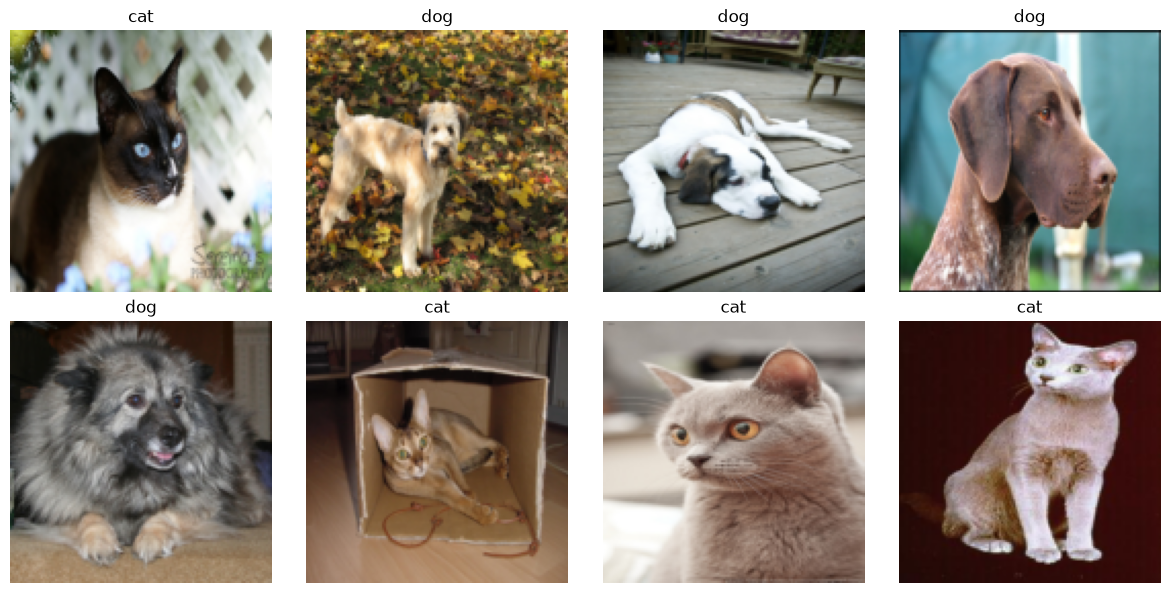

In [7]:
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax, (_, row) in zip(axes.flat, df.sample(min(8, len(df)), random_state=SEED).iterrows()):
    ax.imshow(row["image"])
    ax.set_title(row["labels"])
    ax.axis("off")
for ax in axes.flat[len(df):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

## Step 9 — Turn labels into numbers

Keras works with numeric targets. Here `cat = 0` and `dog = 1`.

In [8]:
label_to_number = {"cat": 0, "dog": 1}
df["target"] = df["labels"].map(label_to_number)
display(df[["id", "labels", "target"]].head())

,id,labels,target
0,Siamese_144,cat,0
1,german_shorthaired_71,dog,1
2,pomeranian_142,dog,1
3,Russian_Blue_8,cat,0
4,Maine_Coon_203,cat,0


## Step 10 — Create training and validation sets

We keep some images aside for checking the model on images it did not train on. Splitting by label keeps both classes represented in each group.

In [9]:
X = np.stack(df["image"].to_numpy()).astype("float32") / 255.0
y = df["target"].to_numpy().astype("float32")

if min(np.bincount(y.astype(int))) < 2:
    raise ValueError("Use at least two photos of each class for a stratified split.")

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)
print("Training images:", len(X_train))
print("Validation images:", len(X_val))
print("Shape of each image:", X_train.shape[1:])

Training images: 16
Validation images: 4
Shape of each image: (128, 128, 3)


## Step 11 — Build a simple CNN

Convolution layers look for visual patterns; pooling makes the representation smaller. The final `Dense(1, activation="sigmoid")` predicts the probability of **dog** (between 0 and 1).

In [10]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(128, 128, 3)),
    tf.keras.layers.Conv2D(16, 3, activation="relu"),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Conv2D(32, 3, activation="relu"),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Conv2D(64, 3, activation="relu"),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(1, activation="sigmoid")
])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,697 (100.38 KB)

 Trainable params: 25,697 (100.38 KB)

 Non-trainable params: 0 (0.00 B)

## Step 12 — Choose how the CNN learns

`binary_crossentropy` compares the predicted probability with the correct cat/dog answer. `accuracy` tracks how often the model is right.

In [11]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

## Step 13 — Train the CNN

The CNN sees training photos in small groups (*batches*). At the end of every epoch, it is evaluated on the untouched validation set.

In [12]:
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=8,
    batch_size=16
)

Epoch 1/8
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 582ms/step - accuracy: 0.5000 - loss: 0.6907 - val_accuracy: 0.5000 - val_loss: 0.6924
Epoch 2/8
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step - accuracy: 0.5000 - loss: 0.6875 - val_accuracy: 0.5000 - val_loss: 0.6921
Epoch 3/8
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - accuracy: 0.5000 - loss: 0.6851 - val_accuracy: 0.5000 - val_loss: 0.6917
Epoch 4/8
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step - accuracy: 0.5000 - loss: 0.6823 - val_accuracy: 0.5000 - val_loss: 0.6909
Epoch 5/8
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - accuracy: 0.5000 - loss: 0.6789 - val_accuracy: 0.5000 - val_loss: 0.6901
Epoch 6/8
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - accuracy: 0.5625 - loss: 0.6749 - val_accuracy: 0.5000 - val_loss: 0.6896
Epoch 7/8
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step - accuracy: 0.5625 - loss: 0.6702 - val_accuracy: 0.5000 - val_loss: 0.6894
Epoch 8/8
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - accuracy: 0.6250 - loss: 0.6649 - val_accuracy: 0.7500 - val_loss: 0.6886


## Step 14 — Plot what happened during training

Compare training and validation accuracy. A large gap can indicate overfitting.

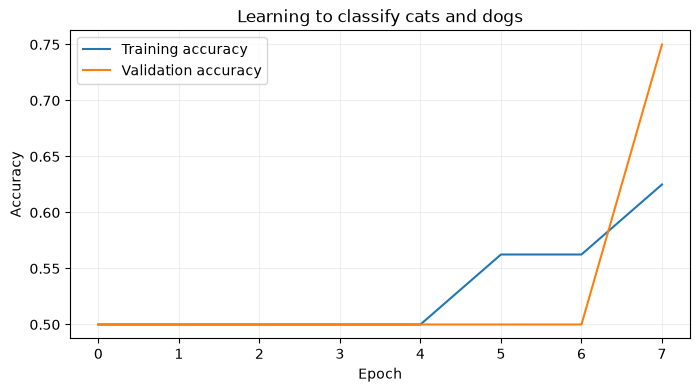

In [13]:
plt.figure(figsize=(8, 4))
plt.plot(history.history["accuracy"], label="Training accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Learning to classify cats and dogs")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

## Step 15 — Predict **one** image

The model outputs a number between 0 and 1. Here, values at least 0.5 mean dog; otherwise cat.

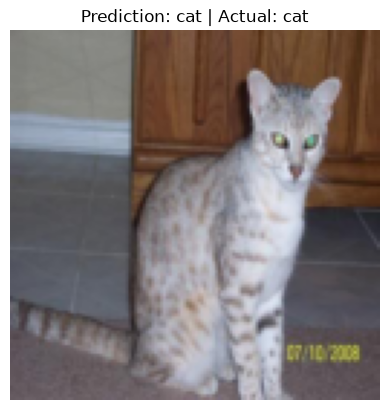

Predicted probability of dog: 49.7%


In [14]:
IMAGE_INDEX = 0  # Change this number to test a different validation image
image = X_val[IMAGE_INDEX]
probability_dog = float(model.predict(image[None, ...], verbose=0)[0, 0])
predicted = "dog" if probability_dog >= 0.5 else "cat"
correct = "dog" if y_val[IMAGE_INDEX] == 1 else "cat"

plt.imshow(image)
plt.title(f"Prediction: {predicted} | Actual: {correct}")
plt.axis("off")
plt.show()
print(f"Predicted probability of dog: {probability_dog:.1%}")

## Step 16 — Check several predictions

Predictions are not guaranteed to be correct, especially with a small training set or only a few epochs.

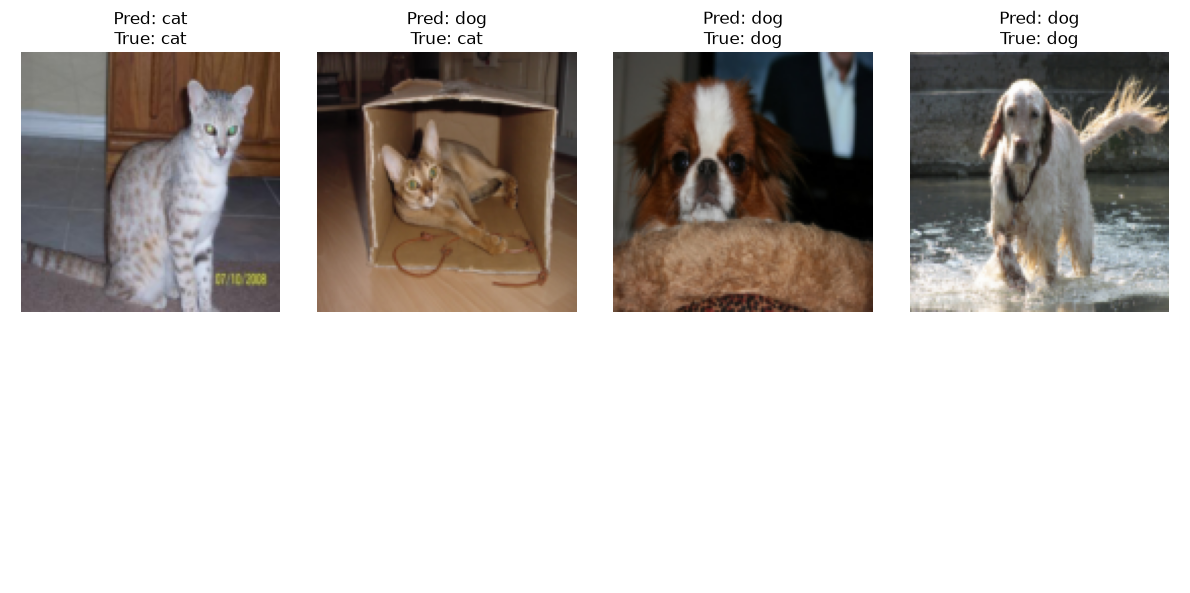

In [15]:
probabilities = model.predict(X_val[:8], verbose=0).flatten()
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for i, ax in enumerate(axes.flat):
    if i >= len(probabilities):
        ax.axis("off")
        continue
    prediction = "dog" if probabilities[i] >= 0.5 else "cat"
    actual = "dog" if y_val[i] == 1 else "cat"
    ax.imshow(X_val[i])
    ax.set_title(f"Pred: {prediction}\nTrue: {actual}")
    ax.axis("off")
plt.tight_layout()
plt.show()

## Step 17 — Evaluation and confusion matrix

This table shows where the classifier makes mistakes: cats labeled as dogs, or dogs labeled as cats.

              precision    recall  f1-score   support

         cat       1.00      0.50      0.67         2
         dog       0.67      1.00      0.80         2

    accuracy                           0.75         4
   macro avg       0.83      0.75      0.73         4
weighted avg       0.83      0.75      0.73         4



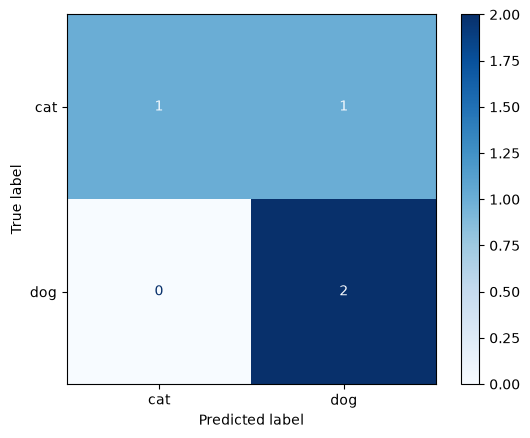

In [16]:
probabilities = model.predict(X_val, verbose=0).flatten()
predicted_numbers = (probabilities >= 0.5).astype(int)
print(classification_report(y_val.astype(int), predicted_numbers,
                            labels=[0, 1], target_names=["cat", "dog"], zero_division=0))
cm = confusion_matrix(y_val.astype(int), predicted_numbers, labels=[0, 1])
ConfusionMatrixDisplay(cm, display_labels=["cat", "dog"]).plot(cmap="Blues")
plt.show()

## Step 18 — Predict a photograph from disk (optional)

Enter the path of a *new* cat or dog photo. The image should not have been used during training if you want an independent test.

In [17]:
NEW_PHOTO = ""  # Example: "my_test_photos/pet.jpg"

if NEW_PHOTO:
    with Image.open(NEW_PHOTO) as photo:
        photo = np.array(photo.convert("RGB").resize(IMAGE_SIZE, Image.Resampling.BILINEAR))
    x_new = photo.astype("float32") / 255.0
    p_dog = float(model.predict(x_new[None, ...], verbose=0)[0, 0])
    plt.imshow(photo)
    plt.title("Predicted: " + ("dog" if p_dog >= 0.5 else "cat"))
    plt.axis("off")
    plt.show()
    print(f"Probability of dog: {p_dog:.1%}")
else:
    print("Enter a path in NEW_PHOTO to classify your own photograph.")

Enter a path in NEW_PHOTO to classify your own photograph.


## Step 19 — Save your trained model

You can reload this Keras file later without training again.

In [18]:
model.save("cat_dog_classifier.keras")
print("Saved cat_dog_classifier.keras")

Saved cat_dog_classifier.keras


## Step 20 — Student exercises

1. Increase `MAX_PER_CLASS` from 100 to 400. Does validation accuracy improve?
2. Change `epochs` from 8 to 12. Does validation accuracy keep increasing?
3. Predict several validation images. Which mistakes does the CNN make?
4. Add `tf.keras.layers.RandomFlip("horizontal")` **after the Input layer** and before the convolution layers. Does augmentation help?
5. Compare this notebook with the **segmentation notebook**: why does this model output just one number, while the segmentation model outputs one prediction per pixel?

**Remember:** For classification, we use one image + one label. For segmentation, we use one image + one pixel mask.